# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [6]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
np.percentile(water, [25, 50, 75])
Q1 = np.percentile(water, 25)
Q3 = np.percentile(water, 75)
IQR = Q3 - Q1
lo = Q1 - 1.5 * IQR
hi = Q3 + 1.5 * IQR
mask = (water < lo) | (water > hi)
water[mask]

array([420.,  95.])

In [5]:
print(f'Q1 = {Q1}')
print(f'Q3 = {Q3}')
print(f'IQR = {IQR}')
print(f'lo = {lo}')
print(f'hi = {hi}')

Q1 = 175.5
Q3 = 185.5
IQR = 10.0
lo = 160.5
hi = 200.5


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [31]:
def iqr_outliers(x, k=1.5):
    # TODO
    xnp = np.array(x)
    Q1 = np.percentile(x, 25)
    Q3 = np.percentile(x, 75)
    IQR = Q3 - Q1
    lo = Q1 - k * IQR
    hi = Q3 + k * IQR
    mask = (x < lo) | (x > hi)
    return mask, lo, hi
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
for k in [1.5, 3]:
    mask, lo, hi = iqr_outliers(sales, k)
    print(f'k = {k}: {mask.all()} lo={lo} hi={hi}')
# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist()==[False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19])[0].any()
print('ผ่านทุก assert')

k = 1.5: False lo=38.375 hi=67.375
k = 3: False lo=27.5 hi=78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

In [36]:
import seaborn as sns

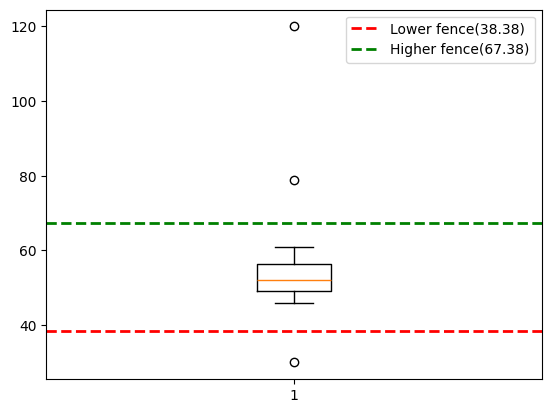

In [45]:
# TODO ข้อ 3
saleboxplot = plt.boxplot(sales, whis=1.5)

# หาค่า lo และ hi ของ sales สำหรับ k=1.5 เพื่อนำมาวาดเส้น
_, lo, hi = iqr_outliers(sales, k=1.5)

# วาดเส้นแนวนอนที่รั้วล่างและรั้วบน
plt.axhline(lo, color='red', linestyle='--', linewidth=2, label=f'Lower fence({lo:.2f})')
plt.axhline(hi, color='green', linestyle='--', linewidth=2, label=f'Higher fence({hi:.2f})')
plt.legend()

In [47]:
lower_whisker = saleboxplot['whiskers'][0].get_ydata()[1]
higher_whisker = saleboxplot['whiskers'][1].get_ydata()[1]


In [48]:
boxplot_fliers = saleboxplot['fliers'][0].get_ydata()

In [49]:
outliers, lo, hi = iqr_outliers(sales, k=1.5)

In [52]:
print(f"รั้วล่าง (lo): {lo:.2f}  | ปลายหนวดล่าง (Lower whisker): {lower_whisker:.2f}")
print(f"รั้วบน (hi):  {hi:.2f} | ปลายหนวดบน (Higher whisker):  {higher_whisker:.2f}")
print("-" * 55)
print(f"Fliers จาก boxplot:      {sorted(boxplot_fliers)}")
print(f"Outliers จากฟังก์ชัน IQR: {sorted(sales[outliers])}")

รั้วล่าง (lo): 38.38  | ปลายหนวดล่าง (Lower whisker): 46.00
รั้วบน (hi):  67.38 | ปลายหนวดบน (Higher whisker):  61.00
-------------------------------------------------------
Fliers จาก boxplot:      [np.float64(30.0), np.float64(79.0), np.float64(120.0)]
Outliers จากฟังก์ชัน IQR: [np.float64(30.0), np.float64(79.0), np.float64(120.0)]


## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [65]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
mask_all, lo_all, hi_all = iqr_outliers(wage['wage_k'])
print(f"4.1 รวมทั้ง 24 คน: lo={lo_all:.2f}, hi={hi_all:.2f}, พบ outlier = {mask_all.sum()} คน")

# TODO 4.2–4.3
wage['is_outlier'] = wage.groupby('occupation')['wage_k'].transform(lambda s: iqr_outliers(s)[0])
print("\n4.2 รายชื่อ outlier แยกตามอาชีพ:")
print(wage[wage['is_outlier']])

# TODO 4.3
def group_stats(s):
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    return pd.Series({
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'รั้วล่าง (lo)': q1 - 1.5 * iqr,
        'รั้วบน (hi)': q3 + 1.5 * iqr
    })

summ = wage.groupby('occupation')['wage_k'].apply(group_stats).unstack()
print("\n4.3 สรุป IQR และรั้วของแต่ละอาชีพ:")
display(summ)

4.1 รวมทั้ง 24 คน: lo=-56.00, hi=130.00, พบ outlier = 0 คน

4.2 รายชื่อ outlier แยกตามอาชีพ:
   occupation  wage_k  is_outlier
7     cleaner      35        True
15      clerk       9        True

4.3 สรุป IQR และรั้วของแต่ละอาชีพ:


,Q1,Q3,IQR,รั้วล่าง (lo),รั้วบน (hi)
occupation,,,,,
cleaner,12.00,14.25,2.25,8.625,17.625
clerk,18.75,21.25,2.50,15.000,25.000
engineer,60.75,65.25,4.50,54.000,72.000


```markdown
###อธิบายสาเหตุที่ผลรวมกับผลรายกลุ่มแตกต่างกัน

* **การวิเคราะห์แบบรวมกลุ่ม (Global):**
  เมื่อนำข้อมูลทุกอาชีพที่มีฐานเงินเดือนแตกต่างกันมากมารวมกัน ค่าความแปรปรวนของข้อมูลจะสูงมาก (มีช่วงตั้งแต่ 9 ไปจนถึง 70) ส่งผลให้เกณฑ์รั้วปกติกว้างผิดปกติ (คือ -56.00 ถึง 130.00) ผลลัพธ์จึง**ไม่พบค่าที่หลุดเกณฑ์เลย (พบ 0 คน)**

* **การวิเคราะห์แบบแยกอาชีพ (Contextual):**
  เมื่อพิจารณาในบริบทของกลุ่มตนเองที่มีฐานเงินเดือนใกล้เคียงกัน เกณฑ์จะแคบลงและสมเหตุสมผลตามความเป็นจริงมากขึ้น ทำให้เราพบจุดผิดปกติเฉพาะกลุ่ม (Contextual Outliers) **จำนวน 2 คน** ได้แก่:
  1. **Cleaner (ค่าจ้าง 35):** ซึ่งได้เงินสูงมากเกินไปเมื่อเทียบกับกลุ่มคนทำความสะอาดทั่วไปที่ได้ราว ๆ 12-15
  2. **Clerk (ค่าจ้าง 9):** ซึ่งได้เงินต่ำเกินไปเมื่อเทียบกับกลุ่มพนักงานออฟฟิศทั่วไปที่ได้ราว ๆ 18-23
```